<a href="https://colab.research.google.com/github/gautamtoni/ScholarRAG/blob/main/sentiment_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import os
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, LSTM, Dense, Dropout, Bidirectional
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: []


In [4]:
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/imdb")

train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

print("Training Shape:", train_df.shape)
print("Testing Shape:", test_df.shape)

train_df.head()

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

... (2 outputs left out)

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Training Shape: (25000, 2)
Testing Shape: (25000, 2)


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [5]:
print("Dataset Information:")
train_df.info()

print("\nMissing Values:")
print(train_df.isnull().sum())

print("\nSentiment Distribution:")
print(train_df["label"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB

Missing Values:
text     0
label    0
dtype: int64

Sentiment Distribution:
label
0    12500
1    12500
Name: count, dtype: int64


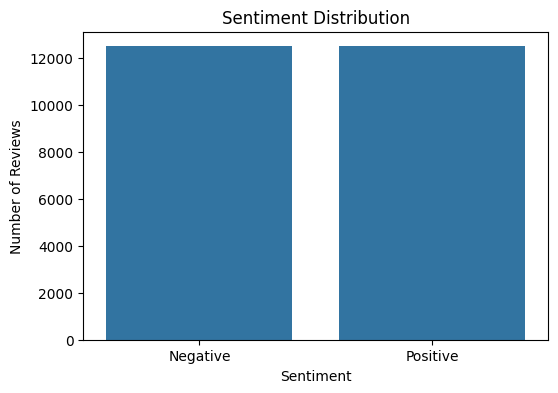

In [6]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=train_df,
    x="label"
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks([0, 1], ["Negative", "Positive"])

plt.show()

In [7]:
train_df["review_length"] = train_df["text"].apply(
    lambda x: len(x.split())
)

print(train_df["review_length"].describe())

count    25000.000000
mean       233.787200
std        173.733032
min         10.000000
25%        127.000000
50%        174.000000
75%        284.000000
max       2470.000000
Name: review_length, dtype: float64


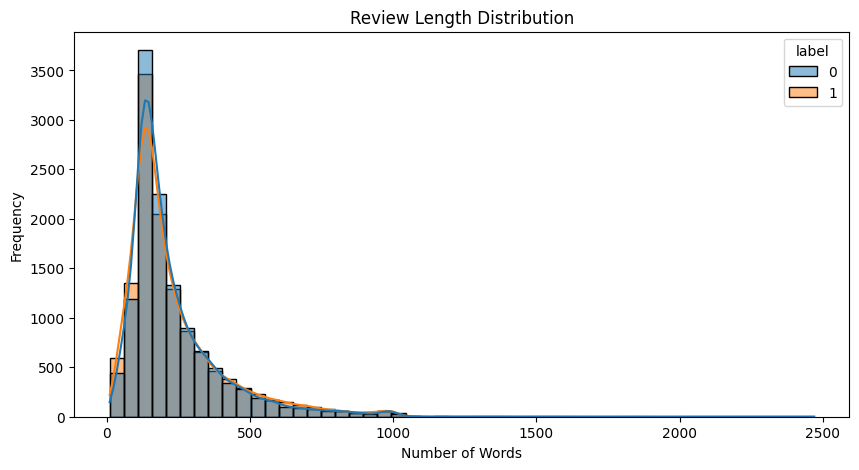

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_df,
    x="review_length",
    hue="label",
    bins=50,
    kde=True
)

plt.title("Review Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [9]:
print("Negative Review:\n")
print(train_df[train_df["label"] == 0]["text"].iloc[0])

print("\n" + "="*80)

print("\nPositive Review:\n")
print(train_df[train_df["label"] == 1]["text"].iloc[0])

Negative Review:

I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few an

In [11]:
import re

def clean_text(text):

    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<br\s*/?>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove unwanted characters
    text = re.sub(r"[^a-zA-Z\s]", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply preprocessing
train_df["clean_text"] = train_df["text"].apply(clean_text)
test_df["clean_text"] = test_df["text"].apply(clean_text)

print("Preprocessing completed!")

print(train_df[["text", "clean_text"]].head(2))

Preprocessing completed!
                                                text  \
0  I rented I AM CURIOUS-YELLOW from my video sto...   
1  "I Am Curious: Yellow" is a risible and preten...   

                                          clean_text  
0  i rented i am curiousyellow from my video stor...  
1  i am curious yellow is a risible and pretentio...  


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    train_df["clean_text"],
    train_df["label"],
    test_size=0.2,
    random_state=42,
    stratify=train_df["label"]
)

# Test data
X_test = test_df["clean_text"]
y_test = test_df["label"]

print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))

Training Samples: 20000
Validation Samples: 5000
Testing Samples: 25000


In [13]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 30000
MAX_LEN = 250

# Initialize tokenizer
tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

# Fit only on training data
tokenizer.fit_on_texts(X_train)

# Convert text into sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Apply padding
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training Shape:", X_train_pad.shape)
print("Validation Shape:", X_val_pad.shape)
print("Testing Shape:", X_test_pad.shape)

print("\nVocabulary Size:", len(tokenizer.word_index))

Training Shape: (20000, 250)
Validation Shape: (5000, 250)
Testing Shape: (25000, 250)

Vocabulary Size: 96521


In [14]:
print("Original Text:")
print(X_train.iloc[0][:300])

print("\nTokenized Sequence:")
print(X_train_seq[0][:30])

print("\nPadded Sequence:")
print(X_train_pad[0][:30])

Original Text:
i have always been a huge james bond fanatic i have seen almost all of the films except for die another day and the world is not enough the graphics for everything or nothing are breathtaking the voice talents wow i love pierce brosnan he is finally bond in a video game he is bond i enjoyed the past

Tokenized Sequence:
[10, 25, 204, 76, 4, 645, 558, 1521, 7022, 10, 25, 105, 216, 31, 5, 2, 95, 543, 15, 834, 153, 253, 3, 2, 187, 7, 21, 191, 2, 2983]

Padded Sequence:
[  10   25  204   76    4  645  558 1521 7022   10   25  105  216   31
    5    2   95  543   15  834  153  253    3    2  187    7   21  191
    2 2983]


In [17]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Embedding, Bidirectional, LSTM,
    Dense, Dropout
)

vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)

lstm_model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=vocab_size, output_dim=128),
    Bidirectional(LSTM(64)),
    Dropout(0.5),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 250, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,947,137 (15.06 MB)

 Trainable params: 3,947,137 (15.06 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [19]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5
    ),

    ModelCheckpoint(
        "best_lstm_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

print("Callbacks configured successfully!")

Callbacks configured successfully!


In [20]:
history = lstm_model.fit(
    X_train_pad,
    np.array(y_train),
    validation_data=(X_val_pad, np.array(y_val)),
    epochs=10,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 111s 346ms/step - accuracy: 0.7260 - loss: 0.5353 - val_accuracy: 0.8362 - val_loss: 0.3938 - learning_rate: 0.0010
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 108s 344ms/step - accuracy: 0.8893 - loss: 0.2887 - val_accuracy: 0.8422 - val_loss: 0.3839 - learning_rate: 0.0010
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 110s 351ms/step - accuracy: 0.9340 - loss: 0.1886 - val_accuracy: 0.8356 - val_loss: 0.4299 - learning_rate: 0.0010
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 111s 354ms/step - accuracy: 0.9495 - loss: 0.1479 - val_accuracy: 0.8146 - val_loss: 0.6120 - learning_rate: 0.0010
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 106s 339ms/step - accuracy: 0.9604 - loss: 0.1115 - val_accuracy: 0.8564 - val_loss: 0.5129 - learning_rate: 5.0000e-04


In [21]:
import os

print("Checkpoint exists:", os.path.exists("best_lstm_model.keras"))

Checkpoint exists: True


In [22]:
from tensorflow.keras.models import load_model

lstm_model = load_model("best_lstm_model.keras")

print("Best LSTM model loaded successfully!")

Best LSTM model loaded successfully!


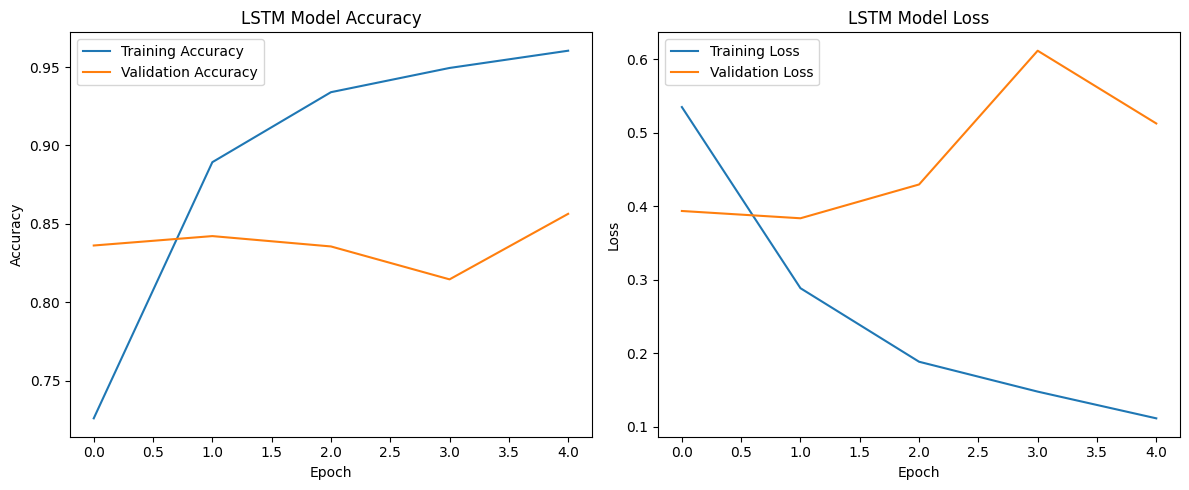

In [23]:
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("LSTM Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [24]:
test_loss, test_accuracy = lstm_model.evaluate(
    X_test_pad,
    np.array(y_test),
    batch_size=64,
    verbose=1
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

391/391 ━━━━━━━━━━━━━━━━━━━━ 34s 86ms/step - accuracy: 0.8332 - loss: 0.4158
Test Loss: 0.4158
Test Accuracy: 83.32 %


782/782 ━━━━━━━━━━━━━━━━━━━━ 34s 43ms/step
              precision    recall  f1-score   support

    Negative       0.90      0.75      0.82     12500
    Positive       0.79      0.91      0.85     12500

    accuracy                           0.83     25000
   macro avg       0.84      0.83      0.83     25000
weighted avg       0.84      0.83      0.83     25000



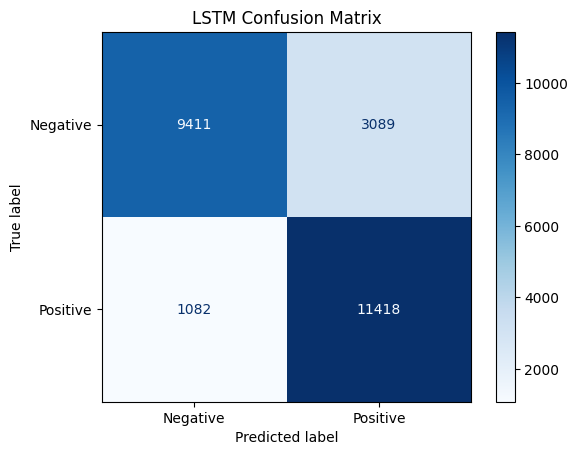

In [25]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predict sentiment probabilities
y_pred_prob = lstm_model.predict(X_test_pad)

# Convert probabilities into binary classes
y_pred = (y_pred_prob > 0.5).astype("int32").flatten()

# Classification report
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("LSTM Confusion Matrix")
plt.show()

In [26]:
import pickle

# Save trained LSTM model
lstm_model.save("sentiment_lstm_model.keras")

# Save fitted tokenizer
with open("sentiment_tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

print("Model and tokenizer saved successfully!")

Model and tokenizer saved successfully!


In [27]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.sequence import pad_sequences
import pickle

# Load saved model
loaded_model = load_model("sentiment_lstm_model.keras")

# Load saved tokenizer
with open("sentiment_tokenizer.pkl", "rb") as file:
    loaded_tokenizer = pickle.load(file)


def predict_sentiment(review):

    # Apply the same preprocessing used during training
    cleaned_review = clean_text(review)

    # Convert text into sequences
    sequence = loaded_tokenizer.texts_to_sequences([cleaned_review])

    # Apply the same padding
    padded_sequence = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Predict sentiment
    prediction = loaded_model.predict(padded_sequence, verbose=0)[0][0]

    sentiment = "Positive" if prediction >= 0.5 else "Negative"

    confidence = prediction if prediction >= 0.5 else 1 - prediction

    print("Review:", review)
    print("Sentiment:", sentiment)
    print("Confidence:", round(float(confidence) * 100, 2), "%")


print("Prediction function created successfully!")

Prediction function created successfully!


In [28]:
positive_review = """
This movie was absolutely fantastic.
The acting was brilliant and the story was amazing.
I really enjoyed watching it.
"""

predict_sentiment(positive_review)

Review: 
This movie was absolutely fantastic.
The acting was brilliant and the story was amazing.
I really enjoyed watching it.

Sentiment: Positive
Confidence: 97.67 %


In [29]:
negative_review = """
This movie was terrible.
The acting was boring and the story was very disappointing.
I hated watching it.
"""

predict_sentiment(negative_review)

Review: 
This movie was terrible.
The acting was boring and the story was very disappointing.
I hated watching it.

Sentiment: Negative
Confidence: 99.38 %


In [30]:
review = input("Enter a movie review: ")

predict_sentiment(review)

Enter a movie review: mersal
Review: mersal
Sentiment: Positive
Confidence: 55.28 %


In [31]:
def predict_sentiment(review):

    cleaned_review = clean_text(review)
    sequence = loaded_tokenizer.texts_to_sequences([cleaned_review])

    padded_sequence = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    prediction = loaded_model.predict(
        padded_sequence, verbose=0
    )[0][0]

    sentiment = "Positive" if prediction >= 0.5 else "Negative"
    confidence = prediction if prediction >= 0.5 else 1 - prediction

    print("Review:", review)
    print("Sentiment:", sentiment)
    print("Confidence:", round(float(confidence) * 100, 2), "%")

    if confidence < 0.60:
        print("Warning: Low confidence. Prediction may be unreliable.")

In [32]:
review = input("Enter a movie review: ")

predict_sentiment(review)

Enter a movie review: ghilli movie awesome
Review: ghilli movie awesome
Sentiment: Positive
Confidence: 82.1 %


In [33]:
import os
import shutil

project_dir = "Sentiment-Analysis-LSTM"

os.makedirs(project_dir, exist_ok=True)
os.makedirs(f"{project_dir}/models", exist_ok=True)
os.makedirs(f"{project_dir}/results", exist_ok=True)

# Copy trained model
shutil.copy(
    "sentiment_lstm_model.keras",
    f"{project_dir}/models/sentiment_lstm_model.keras"
)

# Copy tokenizer
shutil.copy(
    "sentiment_tokenizer.pkl",
    f"{project_dir}/models/sentiment_tokenizer.pkl"
)

print("Project folders created successfully!")

for root, dirs, files in os.walk(project_dir):
    print(root, files)

Project folders created successfully!
Sentiment-Analysis-LSTM []
Sentiment-Analysis-LSTM/models ['sentiment_tokenizer.pkl', 'sentiment_lstm_model.keras']
Sentiment-Analysis-LSTM/results []


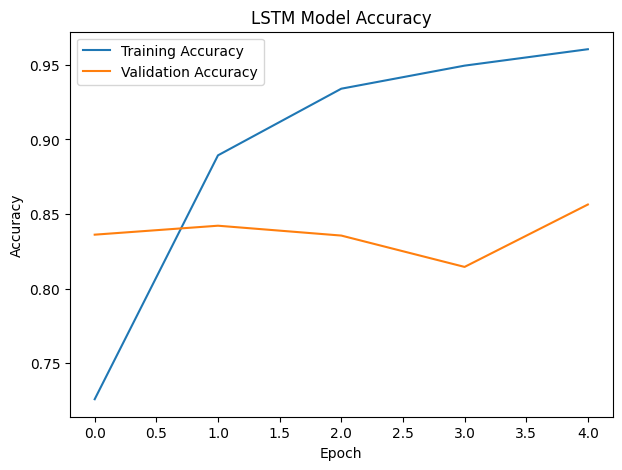

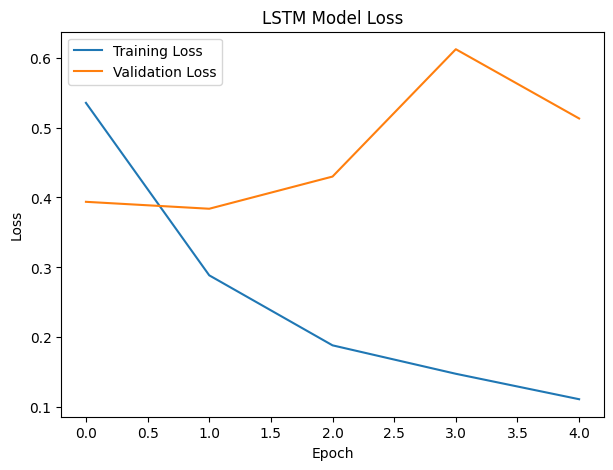

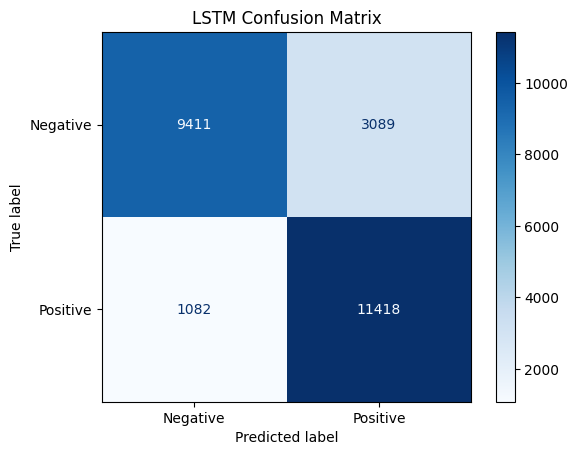

All result graphs saved successfully!


In [34]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

results_dir = "Sentiment-Analysis-LSTM/results"

# 1. Accuracy graph
plt.figure(figsize=(7, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("LSTM Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.savefig(f"{results_dir}/accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Loss graph
plt.figure(figsize=(7, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.savefig(f"{results_dir}/loss.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("LSTM Confusion Matrix")
plt.savefig(f"{results_dir}/confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("All result graphs saved successfully!")

In [35]:
requirements = """
tensorflow
numpy
pandas
matplotlib
scikit-learn
"""

with open(
    "Sentiment-Analysis-LSTM/requirements.txt",
    "w"
) as file:
    file.write(requirements.strip())

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [37]:
readme = '''# Sentiment Analysis using LSTM

## Project Overview
A Deep Learning project that classifies IMDb movie reviews into Positive and Negative sentiments using a Bidirectional LSTM model.

## Dataset
- Dataset: IMDb Movie Reviews
- Source: Hugging Face
- Total reviews: 50,000
- Training reviews: 25,000
- Testing reviews: 25,000
- Classes: Positive and Negative

Dataset: https://huggingface.co/datasets/stanfordnlp/imdb

## Model Architecture
- Embedding Layer: 128 dimensions
- Bidirectional LSTM: 64 units
- Dropout: 0.5
- Dense: 64 units, ReLU
- Dropout: 0.3
- Output: Sigmoid

## Model Performance

| Metric | Result |
|---|---:|
| Test Accuracy | 83.32% |
| Test Loss | 0.4158 |
| Macro Precision | 0.84 |
| Macro Recall | 0.83 |
| Macro F1-score | 0.83 |

## Confusion Matrix

![Confusion Matrix](results/confusion_matrix.png)

## Training Accuracy

![Accuracy](results/accuracy.png)

## Training Loss

![Loss](results/loss.png)

## Prediction Examples

| Review | Prediction | Confidence |
|---|---|---:|
| Fantastic movie and brilliant acting | Positive | 97.67% |
| Terrible movie and disappointing story | Negative | 99.38% |

## Technologies Used
- Python
- TensorFlow and Keras
- NumPy
- Pandas
- Scikit-learn
- Matplotlib
- Google Colab

## Limitations
- Supports English-language sentiment classification.
- Trained on IMDb movie reviews.
- Performance may vary on other domains.
- Confidence scores are not guarantees of correctness.

## Disclaimer
This project is for educational and portfolio purposes only.
'''

with open("Sentiment-Analysis-LSTM/README.md", "w") as file:
    file.write(readme)

print("README.md created successfully!")

README.md created successfully!


In [38]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "Sentiment-Analysis-LSTM",
    "zip",
    root_dir=".",
    base_dir="Sentiment-Analysis-LSTM"
)

print("ZIP created successfully!")

files.download(zip_path)

ZIP created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>